# TCN e TCN-Attention com e sem pré-processamento na previsão de irradiância solar

Este notebook compara a TCN e a TCN-Attention de Honnurvali et al. (2026), com e sem o pré-processamento e a engenharia de atributos (FE) do artigo, com três modelos de referência usados por Santos Júnior et al. (2022): ARIMA, SVR e MLP. Todas as previsões são de 1 passo à frente.

O código está no pacote `irradiancia/`, na raiz do repositório. Neste notebook ficam a configuração, a análise dos dados, as chamadas de treino e os resultados.

| Item | Escolha | Fonte |
|---|---|---|
| Séries | Kaggle (`solar_mw`) e INMET de São Paulo, Florianópolis, Salvador e Fortaleza, de 2016 a 2020 | Honnurvali et al. (2026); Santos Júnior et al. (2022) |
| Divisão | 60/20/20 em ordem cronológica | Santos Júnior et al. (2022, Seção 5) |
| Modelos de referência | ARIMA (AutoARIMA), SVR e MLP, com as grades da Tabela 1 | Santos Júnior et al. (2022) |
| Redes | TCN e TCN-Attention: convolução causal dilatada, atenção aditiva, saída sigmoide, MSE e Adam | Honnurvali et al. (2026, Eq. 2 a 8 e Alg. 1) |
| SEM pré-processamento | falha vira zero no INMET e último valor no Kaggle; Min-Max | Santos Júnior et al. (2022) |
| COM pré-processamento | imputação causal, corte por IQR, defasagens, estatísticas móveis, faixas de intensidade, calendário e meteorologia | Seção 3; Honnurvali et al. (2026, Seções III e IV) |
| Avaliação | RMSE, MAPE, MAE, ARV e IA em [0,1; 0,9], só nas horas medidas | Santos Júnior et al. (2022, Seção 5.2) |
| Repetições e estatística | 10 execuções; Friedman e Nemenyi sobre os 5 datasets | Demšar (2006) |

Seções:
1. Dados
2. Investigação dos dados faltantes
3. Pré-processamento
4. Métricas
5. Modelos de referência
6. Atributos e janelas das TCNs
7. TCN e TCN-Attention
8. Resultados

As referências completas estão no fim.

In [1]:
# Configuração
MODO_RAPIDO = False    # True: 2 execuções, 3 épocas e grades com uma configuração, só para testar o código mais rápido
N_EXECUCOES = 2 if MODO_RAPIDO else 10
MAX_EPOCAS = 3 if MODO_RAPIDO else 200

ANOS_INMET = range(2016, 2021)     # 2016 a 2020 nas quatro estações
INICIO_KAGGLE = "2016-01-01"       # a série do Kaggle termina em 03/08/2020

# Pasta dos resultados, dentro de notebooks/. Execuções já gravadas nela são puladas.
# No Colab, para não perder nada se a sessão cair, use o Google Drive:
#   from google.colab import drive; drive.mount("/content/drive")
#   PASTA_RESULTADOS = "/content/drive/MyDrive/tcn_fe/resultados_2016_2020_v2"
PASTA_RESULTADOS = "resultados_2016_2020_v2"

In [2]:
# No Colab, clone o repositório e entre na pasta notebooks antes:
#   !git clone https://github.com/arqowl/tcn-fe-irradiancia.git
#   %cd tcn-fe-irradiancia/notebooks
%pip install -q statsforecast
import sys
import warnings
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "irradiancia").is_dir())
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR

from irradiancia import analise, graficos
from irradiancia.dados import ESTACOES_INMET, CarregadorINMET, CarregadorKaggle
from irradiancia.estatistica import friedman_nemenyi
from irradiancia.experimento import Experimento
from irradiancia.modelos import PrevisorARIMA, PrevisorJanelado, PrevisorTCN, RedeTCN, RedeTCNAtencao, Treinador
from irradiancia.preparacao import PreparadorTCN
from irradiancia.preprocessamento import CorteIQR, ImputacaoCausal, PreenchimentoSimples
from irradiancia.registro import RegistroDeResultados, tabela_media_dp

DADOS = RAIZ / "notebooks" / "dados"
PASTA = Path(PASTA_RESULTADOS)
if not PASTA.is_absolute():
    PASTA = RAIZ / "notebooks" / PASTA
PASTA.mkdir(parents=True, exist_ok=True)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", DISPOSITIVO, "| execuções:", N_EXECUCOES, "| resultados em", PASTA)

Note: you may need to restart the kernel to use updated packages.
dispositivo: cuda | execuções: 10 | resultados em /workspace/notebooks/resultados_2016_2020_v2


## 1. Dados
As séries do INMET vêm dos arquivos anuais de cada estação, guardados em `notebooks/dados/` no formato do repositório de Santos Júnior et al. (2022). O script `ferramentas/baixar_inmet.py` gera esses arquivos a partir dos pacotes do portal do INMET. Ficam as horas de 09 a 21 UTC (06 às 18 h locais), 13 por dia, como no artigo.

A série do Kaggle é a `solar_mw`, com 24 amostras por dia. O arquivo tem 13,3 anos, mas foi usado o mesmo período das cidades. As variáveis meteorológicas desse arquivo só existem nas últimas 2920 horas e por isso ficam de fora.

Com a divisão 60/20/20, as cidades treinam em 2016 a 2018, validam em 2019 e testam em 2020. A célula confere que o treino cobre os 12 meses do ano para fechar quaisquer sazonalidades.

In [3]:
carregador = CarregadorINMET(DADOS)
ESTACOES = {e.nome: e for e in ESTACOES_INMET}
SERIES = {"Kaggle": CarregadorKaggle(DADOS).carregar(INICIO_KAGGLE)}
SERIES.update({nome: carregador.carregar(estacao, ANOS_INMET) for nome, estacao in ESTACOES.items()})

for serie in SERIES.values():
    print(serie.resumo())
    assert serie.valores.index[:serie.divisao.treino].month.nunique() == 12, f"{serie.nome}: treino sem os 12 meses"

Kaggle         n =  40225 | treino 01/01/2016 a 02/10/2018 (24135, 12/12 meses) | validação 8045 | teste 02/09/2019 a 03/08/2020 (8045, 25 sem medição) | variáveis meteorológicas: 0
Sao Paulo      n =  23751 | treino 01/01/2016 a 01/01/2019 (14251, 12/12 meses) | validação 4750 | teste 01/01/2020 a 31/12/2020 (4750, 162 sem medição) | variáveis meteorológicas: 5
Florianopolis  n =  23751 | treino 01/01/2016 a 01/01/2019 (14251, 12/12 meses) | validação 4750 | teste 01/01/2020 a 31/12/2020 (4750, 56 sem medição) | variáveis meteorológicas: 5
Salvador       n =  23751 | treino 01/01/2016 a 01/01/2019 (14251, 12/12 meses) | validação 4750 | teste 01/01/2020 a 31/12/2020 (4750, 43 sem medição) | variáveis meteorológicas: 5
Fortaleza      n =  23751 | treino 01/01/2016 a 01/01/2019 (14251, 12/12 meses) | validação 4750 | teste 01/01/2020 a 31/12/2020 (4750, 49 sem medição) | variáveis meteorológicas: 5


## 2. Investigação dos dados faltantes
Os arquivos do INMET deixam a radiação em branco quando não há valor. Antes de escolher um tratamento, é preciso saber o que cada branco significa: uma falha do sensor ou uma hora sem Sol. As duas coisas pedem tratamentos diferentes.

### 2.1 Quanto falta
A tabela separa os brancos pela posição do Sol, calculada com a irradiação no topo da atmosfera (Seção 2.3). "Falha com Sol" é um branco numa hora em que havia Sol.

In [4]:
TABELAS_BRUTAS = {nome: carregador.ler(estacao, ANOS_INMET) for nome, estacao in ESTACOES.items()}
display(analise.faltantes_por_ano(TABELAS_BRUTAS))

horas  sem dado (%)  Sol abaixo do horizonte (%)  \
estação       ano                                                      
Sao Paulo     2016   4758           8.2                          4.4   
              2017   4745           8.4                          4.4   
              2018   4745           6.4                          4.1   
              2019   4745           7.7                          4.1   
              2020   4758           7.1                          3.7   
Florianopolis 2016   4758           7.4                          6.0   
              2017   4745           8.5                          6.1   
              2018   4745           9.1                          6.0   
              2019   4745          10.1                          5.9   
              2020   4758           7.2                          6.1   
Salvador      2016   4758           7.3                          0.5   
              2017   4745           1.7                          0.5   
              2018   4745           1.7                          0.5   
              2019   4745           1.3                          0.4   
              2020   4758           1.4                          0.5   
Fortaleza     2016   4758          13.2                          0.0   
              2017   4745           1.5                          0.0   
              2018   4745           4.3                          0.0   
              2019   4745          26.7                          0.0   
              2020   4758           1.0                          0.0   

                    falha com Sol (%)  maior falha com Sol (dias)  
estação       ano                                                  
Sao Paulo     2016                3.8                         2.5  
              2017                4.0                         0.9  
              2018                2.3                         0.4  
              2019                3.6                         0.3  
              2020                3.4                         0.3  
Florianopolis 2016                1.4                         0.1  
              2017                2.4                         0.2  
              2018                3.1                         0.1  
              2019                4.2                         0.2  
              2020                1.2                         0.1  
Salvador      2016                6.8                        20.6  
              2017                1.2                         0.1  
              2018                1.2                         0.6  
              2019                0.9                         0.2  
              2020                0.9                         0.1  
Fortaleza     2016               13.2                         1.5  
              2017                1.5                         0.2  
              2018                4.3                         0.3  
              2019               26.7                        73.2  
              2020                1.0                         0.1

Em São Paulo e Florianópolis, boa parte dos brancos cai em horas com o Sol abaixo do horizonte. As falhas com Sol ficam abaixo de 4,5% das horas na maioria dos anos. As exceções são Salvador em 2016 (6,8%, com uma falha de 21 dias) e Fortaleza em 2016 (13,2%) e 2019 (26,7%, com uma falha de 73 dias).

### 2.2 Em que hora falta

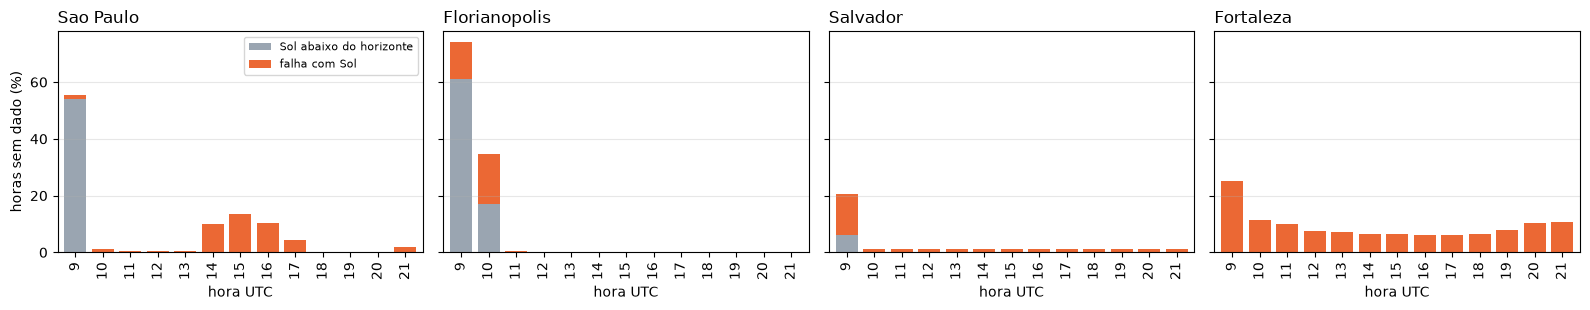

In [5]:
POR_HORA = {nome: analise.faltantes_por_hora(tabela) for nome, tabela in TABELAS_BRUTAS.items()}
fig = graficos.faltantes_por_hora(POR_HORA, PASTA / "faltantes_por_hora.png")

Os brancos se concentram às 09 UTC (06 h locais) e, em Florianópolis, também às 10 UTC. Nessas horas o Sol ainda não nasceu em boa parte do ano, sobretudo no inverno e mais ao sul. Em Salvador e Fortaleza, mais perto do equador, o Sol nasce durante a hora das 09 UTC, e os brancos dessa hora contam como falha, embora o valor perdido seja pequeno. Em Fortaleza, a falha longa de 2019 aparece como uma faixa de 6% a 10% em todas as horas. São Paulo tem outro padrão: falhas entre 14 e 16 UTC, com o Sol alto.

### 2.3 A que intervalo se refere o valor de cada hora?
Para separar noite de falha, é preciso saber a que intervalo de uma hora se refere o valor gravado às HH UTC. A célula testa cinco hipóteses, deslocando o intervalo de meia em meia hora, com a irradiação no topo da atmosfera $G_0$ (DUFFIE; BECKMAN, 2013). $G_0$ vale zero quando o Sol fica abaixo do horizonte durante a hora inteira.

Na hipótese certa, duas coisas precisam valer:
1. nenhuma hora com o Sol abaixo do horizonte tem radiação medida;
2. o índice de claridade $k = G/G_0$ dos dias limpos (percentil 90 de cada hora) não passa de 1, porque a radiação na superfície não pode ser maior que a do topo da atmosfera.

In [6]:
display(analise.conferir_convencao_horaria(TABELAS_BRUTAS, ESTACOES))

horas com Sol abaixo do horizonte  \
estação       intervalo                                            
Sao Paulo     HH−2 a HH−1                                   2907   
              HH−1,5 a HH−0,5                               2025   
              HH−1 a HH                                     1080   
              HH−0,5 a HH+0,5                                860   
              HH a HH+1                                      885   
Florianopolis HH−2 a HH−1                                   3287   
              HH−1,5 a HH−0,5                               2230   
              HH−1 a HH                                     1460   
              HH−0,5 a HH+0,5                               1040   
              HH a HH+1                                     1080   
Salvador      HH−2 a HH−1                                   1947   
              HH−1,5 a HH−0,5                               1155   
              HH−1 a HH                                      120   
              HH−0,5 a HH+0,5                               1020   
              HH a HH+1                                     1602   
Fortaleza     HH−2 a HH−1                                   1827   
              HH−1,5 a HH−0,5                               1297   
              HH−1 a HH                                        0   
              HH−0,5 a HH+0,5                                755   
              HH a HH+1                                     1827   

                               dessas, com radiação > 50 kJ/m²  k às 10 UTC  \
estação       intervalo                                                       
Sao Paulo     HH−2 a HH−1                                  715        42.82   
              HH−1,5 a HH−0,5                               78        10.41   
              HH−1 a HH                                      0         0.78   
              HH−0,5 a HH+0,5                               10         0.39   
              HH a HH+1                                    327         0.28   
Florianopolis HH−2 a HH−1                                  256        13.87   
              HH−1,5 a HH−0,5                                1         1.79   
              HH−1 a HH                                      0         0.37   
              HH−0,5 a HH+0,5                              120         0.24   
              HH a HH+1                                    520         0.18   
Salvador      HH−2 a HH−1                                  559        38.92   
              HH−1,5 a HH−0,5                                0         0.72   
              HH−1 a HH                                      0         0.29   
              HH−0,5 a HH+0,5                               13         0.20   
              HH a HH+1                                    433         0.16   
Fortaleza     HH−2 a HH−1                                   53         5.04   
              HH−1,5 a HH−0,5                               12         0.69   
              HH−1 a HH                                      0         0.33   
              HH−0,5 a HH+0,5                              492         0.23   
              HH a HH+1                                   1382         0.18   

                               k às 12 UTC  k às 14 UTC  k às 16 UTC  \
estação       intervalo                                                
Sao Paulo     HH−2 a HH−1             1.62         1.12         0.92   
              HH−1,5 a HH−0,5         1.10         1.00         0.90   
              HH−1 a HH               0.90         0.92         0.91   
              HH−0,5 a HH+0,5         0.77         0.87         0.93   
              HH a HH+1               0.69         0.84         0.97   
Florianopolis HH−2 a HH−1             1.21         0.88         0.78   
              HH−1,5 a HH−0,5         0.80         0.79         0.77   
              HH−1 a HH               0.64         0.74         0.77   
              HH−0,5 a HH+0,5         0.55         0.70         0.78   
   

O intervalo de HH − 1 a HH é o único que passa nos dois critérios nas quatro estações. Com o intervalo uma hora para trás, $k$ passa de 1 às 10 UTC em todas as estações. Com meia hora para trás, Salvador ainda passa, mas São Paulo e Florianópolis têm $k$ acima de 1 às 10 UTC, e Fortaleza tem horas noturnas com radiação. Com o intervalo deslocado para frente, aparecem horas noturnas com radiação, e $k$ passa de 1 às 20 UTC em todas as estações. O valor das HH UTC é, portanto, a radiação acumulada entre HH − 1 e HH. Um branco com o Sol abaixo do horizonte quer dizer radiação zero, e `CarregadorINMET.carregar` já grava zero nesses casos.

### 2.4 As falhas com Sol caem em horas comuns?

In [7]:
display(analise.vizinhanca_das_falhas(TABELAS_BRUTAS))

,falhas entre 13 e 17 UTC,mediana antes da falha,mediana dessas horas,percentil 95 dessas horas,falhas de até 3 h (%)
estação,,,,,
Sao Paulo,706,3678.0,2566.0,3800.0,78.0
Florianopolis,2,1209.0,2003.0,3655.0,100.0
Salvador,114,2363.0,2609.0,3624.0,6.0
Fortaleza,587,1770.0,2198.0,2919.0,20.0


Em São Paulo, a radiação medida logo antes de uma falha de meio do dia é bem maior que a mediana dessas horas e fica perto do percentil 95: as falhas aparecem em horas de Sol forte. A contagem de valores altos ajuda a entender por quê.

In [8]:
display(analise.valores_altos(TABELAS_BRUTAS))

,3600 a 3700,3700 a 3800,3800 a 3900,3900 a 4000,4000 a 4100,4100 a 4200,4200 a 5000,maior valor medido
estação,,,,,,,,
Sao Paulo,249,277,253,183,0,0,0,3999.1
Florianopolis,213,210,115,36,1,2,0,4156.0
Salvador,288,179,44,11,1,1,0,4158.8
Fortaleza,0,0,0,0,0,0,0,3253.7


Em São Paulo, a contagem vai de quase duzentas horas na faixa de 3.900 a 4.000 kJ/m² para nenhuma acima de 4.000. Florianópolis e Salvador têm valores acima desse limite. O padrão é o de um corte: em São Paulo, valores acima de 4.000 kJ/m² parecem ter sido descartados. Os arquivos não documentam esse limite. Na terminologia de Little e Rubin (2019), a falta não é completamente aleatória, porque depende do próprio valor. Preencher com a média ou a mediana do horário subestimaria esses buracos.

### 2.5 O que o preenchimento com zero faz com o teste

In [9]:
display(analise.falhas_no_teste(SERIES))

,alvos no teste,sem medição,sem medição (%),sem medição entre 13 e 17 UTC
dataset,,,,
Kaggle,8045,25,0.3,5
Sao Paulo,4750,162,3.4,133
Florianopolis,4750,56,1.2,0
Salvador,4750,43,0.9,1
Fortaleza,4750,49,1.0,1


Com o preenchimento por zero, cada falha do teste vira um zero em pleno dia. Um modelo que acerta a radiação real dessa hora é punido como se tivesse errado por milhares de kJ/m², e um modelo que repete o zero da hora anterior é premiado. Em São Paulo, são mais de cem horas assim no teste.

### 2.6 Decisão
- Sol abaixo do horizonte durante a hora inteira: radiação zero, nas duas condições. É um fato físico, não uma estimativa.
- Falha com Sol na condição SEM: zero, como em Santos Júnior et al. (2022). É a série sem tratamento.
- Falha com Sol na condição COM: imputação causal pelo índice de claridade (Seção 3).
- Avaliação de todos os modelos: a validação e o teste usam só as horas medidas (Seção 4). Nenhum modelo é comparado com um valor que não existe.

A média ou a mediana da série inteira não serviria aqui, porque daria o mesmo valor ao amanhecer e ao meio-dia. A mediana entra onde faz sentido: a do mesmo horário nos dias anteriores, que é a variação diurna média de Falge et al. (2001).

## 3. Pré-processamento
### 3.1 Imputação causal
O índice de claridade é a razão entre a radiação medida e a irradiação no topo da atmosfera (DUFFIE; BECKMAN, 2013):

$$k_t = \frac{G_t}{G_{0,t}}$$

$G_{0,t}$ só depende da data, da hora e das coordenadas da estação. Então, para estimar $G_t$ numa falha, basta estimar $k_t$:
1. o $k$ da última hora medida no mesmo dia;
2. se o dia ainda não tem medição, a mediana de $k$ no mesmo horário dos 14 dias anteriores (FALGE et al., 2001);
3. se a falha passa de 14 dias, a última mediana conhecida.

A estimativa é $\hat G_t = \hat k_t \cdot G_{0,t}$. Ela acompanha o ciclo do dia, pelo $G_{0,t}$, e o céu daquele dia, pelo $k$. Todos os passos usam só o passado, então a imputação de uma hora do teste nunca usa valores posteriores a ela. No Kaggle e nas variáveis meteorológicas não existe $G_{0,t}$, e os mesmos passos são aplicados ao próprio valor.

O gráfico mostra três dias do teste de São Paulo, escolhidos por terem mais falhas de meio do dia. A curva "sem limite" é a imputação só com os três passos acima.

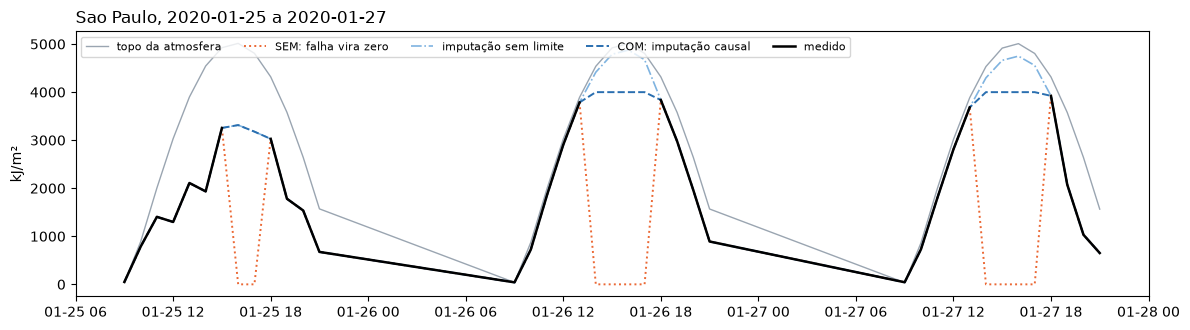

In [10]:
serie = SERIES["Sao Paulo"]
sem = PreenchimentoSimples().aplicar(serie)
com = ImputacaoCausal().aplicar(serie)
sem_limite = ImputacaoCausal(limitar=False).aplicar(serie)

teste = serie.valores.iloc[-serie.divisao.teste:]
falhas_meio_do_dia = teste.isna() & teste.index.hour.isin(range(13, 18))
dia = falhas_meio_do_dia.groupby(teste.index.normalize()).sum().idxmax()
fig = graficos.efeito_do_tratamento(serie, sem, com, f"{dia - pd.Timedelta(days=1):%Y-%m-%d}",
                                    f"{dia + pd.Timedelta(days=1):%Y-%m-%d}", sem_limite=sem_limite,
                                    caminho=PASTA / "efeito_do_tratamento.png")

Sem limite, a imputação chega perto do topo da atmosfera nos dias mais limpos. O motivo está nas horas medidas antes da falha. Nos dias limpos, o $k$ de São Paulo já fica perto de 0,9 no fim da manhã (tabela da Seção 2.3), e repeti-lo ao meio-dia, quando $G_0$ é maior, dá valores acima de qualquer medição da estação. A tabela compara as duas versões nas falhas de meio do dia do teste.

In [11]:
falhas = serie.valores.isna() & serie.valores.index.hour.isin(range(13, 18))
falhas_teste = falhas & (serie.valores.index >= serie.indice_teste[0])
display(pd.DataFrame({
    "sem limite": sem_limite[falhas_teste].describe()[["mean", "max"]],
    "com limite": com[falhas_teste].describe()[["mean", "max"]],
}).T.rename(columns={"mean": "média imputada", "max": "maior valor imputado"})
  .assign(**{"maior valor medido na estação": serie.valores.max()}).round(0))

,média imputada,maior valor imputado,maior valor medido na estação
sem limite,3975.0,4875.0,3999.0
com limite,3772.0,3999.0,3999.0


Por isso a imputação tem um quarto passo: a estimativa fica entre o menor e o maior valor medidos até aquele instante. É um limite causal e impede valores que a estação nunca registrou. Em São Paulo, onde as falhas parecem ser valores acima de 4.000 kJ/m² descartados (Seção 2.4), o limite deixa a estimativa um pouco abaixo do valor real provável. Como essas horas ficam fora da avaliação, isso só afeta a entrada e o treino da condição COM.

### 3.2 Conferência: a imputação não olha o futuro
A célula troca todos os valores posteriores a um instante por uma constante e imputa de novo. Se o método for causal, nada até aquele instante pode mudar.

In [12]:
corte = serie.valores.index[serie.divisao.treino + 500]
futuro_trocado = serie.valores.mask(serie.valores.index > corte, 1234.0)
de_novo = ImputacaoCausal().imputar(futuro_trocado, serie.irradiacao_topo)
igual = np.allclose(com[:corte], de_novo[:corte])
print(f"valores até {corte} iguais nas duas imputações: {igual}")
assert igual

valores até 2019-02-08 18:00:00 iguais nas duas imputações: True


### 3.3 Valores extremos
Na condição COM, o alvo e as variáveis meteorológicas passam pelo corte de Tukey (1977), como em Honnurvali et al. (2026): cada valor fica limitado a $[Q_1 - 1{,}5\,\mathrm{IQR},\ Q_3 + 1{,}5\,\mathrm{IQR}]$, com quartis do treino. A tabela mostra quanto o corte altera em cada coluna.

In [13]:
linhas = {}
for nome in ESTACOES:
    s = SERIES[nome]
    imputacao = ImputacaoCausal()
    tabela = pd.concat([imputacao.aplicar(s).rename("alvo"), s.exogenas.apply(imputacao.imputar)], axis=1)
    cortada = CorteIQR(s.divisao.treino).aplicar(tabela)
    linhas[nome] = (cortada != tabela).mean().mul(100).round(1)
display(pd.DataFrame(linhas).T.rename_axis("% de valores alterados"))

,alvo,temp,umid,pres,vento,chuva
% de valores alterados,,,,,,
Sao Paulo,0.0,0.1,0.0,0.4,0.8,7.1
Florianopolis,0.0,0.8,0.3,0.2,1.3,8.8
Salvador,0.0,0.0,0.0,0.2,3.1,9.7
Fortaleza,0.0,0.1,0.0,0.2,0.0,7.7


O corte quase não mexe na radiação. Na chuva, a maioria das horas tem zero, então $Q_1 = Q_3 = 0$ e o corte zera toda hora com chuva. É o procedimento do artigo, mantido como está. A consequência é que a chuva deixa de informar o modelo na condição COM.

## 4. Métricas
As fórmulas são as de Santos Júnior et al. (2022, Seção 5.2):

| Métrica | Fórmula |
|---|---|
| RMSE | $\sqrt{\frac{1}{N}\sum (y_t-\hat y_t)^2}$ |
| MAPE | $\frac{100}{N}\sum \left|\frac{y_t-\hat y_t}{y_t}\right|$, sem os instantes com $y_t = 0$ |
| MAE | $\frac{1}{N}\sum \lvert y_t-\hat y_t\rvert$ |
| ARV | $\frac{\sum (y_t-\hat y_t)^2}{\sum (\hat y_t-\bar y)^2}$ |
| IA | $1-\frac{\sum (y_t-\hat y_t)^2}{\sum (\lvert\hat y_t-\bar y\rvert+\lvert y_t-\bar y\rvert)^2}$ |

Antes do cálculo, real e previsto vão para $[0{,}1;\ 0{,}9]$ com o mínimo e o máximo da série inteira, como na Tabela 3 do mesmo artigo. A soma corre só sobre os instantes medidos (Seção 2.6). A validação usada na busca em grade e na parada antecipada segue a mesma regra.

Cada execução é gravada em `metricas.csv` e em `previsoes/` assim que termina. Se a máquina cair, basta rodar o notebook de novo.

In [14]:
registro = RegistroDeResultados(PASTA)
experimento = Experimento(SERIES, registro, N_EXECUCOES)

def reduzir(grade):
    # No modo rápido, só a primeira opção de cada hiperparâmetro.
    return {k: v[:1] for k, v in grade.items()} if MODO_RAPIDO else grade

## 5. Modelos de referência
Os três rodam sempre na condição SEM, sobre a série do INMET com as falhas em zero, como em Santos Júnior et al. (2022). SVR e MLP recebem janelas de 12 defasagens. Santos Júnior et al. (2022, Seção 5.1) chegam a essa janela pelo gráfico de autocorrelação. Com 12 lags e o alvo, a janela cobre um dia de 13 horas.

| Modelo | Implementação | Hiperparâmetros (Tabela 1) | Determinístico |
|---|---|---|---|
| ARIMA | `PrevisorARIMA`, com o AutoARIMA do StatsForecast | ordem (p, d, q) pelo método *stepwise* | sim |
| SVR | `PrevisorJanelado` com `sklearn.svm.SVR` | RBF; C ∈ {10, 100, 1000}; γ ∈ {0,1; 0,01; 0,001}; ε ∈ {0,1; 0,01; 0,001} | sim |
| MLP | `PrevisorJanelado` com `sklearn.neural_network.MLPRegressor` | 1 camada oculta sigmoide, L-BFGS; {20, 50, 100} neurônios; tol ∈ {1e-3, 1e-4, 1e-5} | não |

Em modelos determinísticos, as 10 execuções dão o mesmo resultado (SANTOS JÚNIOR et al., 2022, Seção 5.4).

### 5.1 ARIMA
$$\phi(B)\,(1-B)^d\,y_t = c + \theta(B)\,\varepsilon_t$$

A ordem é escolhida pelo AICc no treino, com o método de Hyndman e Khandakar (2008). No teste, os parâmetros ficam fixos e cada previsão usa as observações até $t-1$.

In [15]:
experimento.rodar([PrevisorARIMA()])

Kaggle         ARIMA                    RMSE 0.0125 ± 0.0000  ordem (p, d, q) = (4, 1, 1)
Sao Paulo      ARIMA                    RMSE 0.1365 ± 0.0000  ordem (p, d, q) = (2, 0, 2)
Florianopolis  ARIMA                    RMSE 0.0759 ± 0.0000  ordem (p, d, q) = (5, 1, 1)
Salvador       ARIMA                    RMSE 0.0886 ± 0.0000  ordem (p, d, q) = (5, 1, 1)
Fortaleza      ARIMA                    RMSE 0.0819 ± 0.0000  ordem (p, d, q) = (5, 1, 1)


### 5.2 SVR
$$\hat y(\mathbf x)=\sum_i(\alpha_i-\alpha_i^*)\,K(\mathbf x_i,\mathbf x)+b,\qquad K(\mathbf x_i,\mathbf x)=\exp\!\left(-\gamma\,\lVert\mathbf x_i-\mathbf x\rVert^2\right)$$

A busca testa as 27 configurações da grade e escolhe a de menor RMSE na validação. Como o SVR é determinístico, cada configuração é ajustada uma vez.

In [16]:
GRADE_SVR = {"C": [10, 100, 1000], "gamma": [0.1, 0.01, 0.001], "epsilon": [0.1, 0.01, 0.001],
             "kernel": ["rbf"], "tol": [0.001], "time_window": [12]}
svr = PrevisorJanelado("SVR", SVR(max_iter=10000), reduzir(GRADE_SVR), execucoes_na_busca=1, deterministico=True)
experimento.rodar([svr])

Kaggle         SVR                      RMSE 0.0124 ± 0.0000  {'C': 10, 'epsilon': 0.01, 'gamma': 0.01, 'kernel': 'rbf', 'tol': 0.001}
Sao Paulo      SVR                      RMSE 0.0993 ± 0.0000  {'C': 10, 'epsilon': 0.1, 'gamma': 0.1, 'kernel': 'rbf', 'tol': 0.001}
Florianopolis  SVR                      RMSE 0.0704 ± 0.0000  {'C': 10, 'epsilon': 0.1, 'gamma': 0.1, 'kernel': 'rbf', 'tol': 0.001}
Salvador       SVR                      RMSE 0.0798 ± 0.0000  {'C': 10, 'epsilon': 0.001, 'gamma': 0.1, 'kernel': 'rbf', 'tol': 0.001}
Fortaleza      SVR                      RMSE 0.0719 ± 0.0000  {'C': 10, 'epsilon': 0.1, 'gamma': 0.1, 'kernel': 'rbf', 'tol': 0.001}


### 5.3 MLP
$$\hat y(\mathbf x)=\mathbf w_2^\top\,\sigma(\mathbf W_1\mathbf x+\mathbf b_1)+b_2,\qquad \sigma(z)=\frac{1}{1+e^{-z}}$$

Cada uma das 9 configurações é avaliada pela média de 10 ajustes. Nas execuções finais, a semente muda só os pesos iniciais.

In [17]:
GRADE_MLP = {"hidden_layer_sizes": [20, 50, 100], "tol": [0.001, 0.0001, 0.00001],
             "max_iter": [1000], "time_window": [12]}
mlp = PrevisorJanelado("MLP", MLPRegressor(activation="logistic", solver="lbfgs"), reduzir(GRADE_MLP),
                       execucoes_na_busca=N_EXECUCOES)
experimento.rodar([mlp])

Kaggle         MLP                      RMSE 0.0134 ± 0.0002  {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05}
Sao Paulo      MLP                      RMSE 0.1001 ± 0.0006  {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05}
Florianopolis  MLP                      RMSE 0.0680 ± 0.0003  {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05}
Salvador       MLP                      RMSE 0.0779 ± 0.0003  {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05}
Fortaleza      MLP                      RMSE 0.0711 ± 0.0003  {'hidden_layer_sizes': 20, 'max_iter': 1000, 'tol': 1e-05}


## 6. Atributos e janelas das TCNs
`PreparadorTCN` monta os dados das duas condições:
- SEM: só o alvo, com as falhas em zero, em Min-Max. Uma variável por passo de tempo.
- COM: imputação causal do alvo e da meteorologia, corte por IQR e os atributos de Honnurvali et al. (2026, Fig. 2 e Tabela 1). São defasagens de 1, 2, 3 e 4 passos e de 1, 2 e 7 dias, média, máximo e mínimo móveis de 1 dia e médias exponenciais de meio dia e de 1 dia. Também entram a interação do alvo com a temperatura, cinco faixas de intensidade pelos quintis do treino, hora, dia da semana e mês em one-hot, e as variáveis meteorológicas. Depois, Min-Max.

No artigo, "1 dia" são 24 passos. Nas cidades, são 13. A escala, os quartis e as faixas usam só o treino, e cada atributo da linha $t$ usa só valores até $t$.

A janela de entrada tem 48 passos no Kaggle, o *lookback* de Honnurvali et al. (2026, Seção IV.F), e 12 nas cidades, a mesma dos modelos de referência. O teste é o mesmo para todos os modelos.

In [18]:
preparador = PreparadorTCN()
for nome, serie in SERIES.items():
    for condicao in ("SEM", "COM"):
        dados = preparador.preparar(serie, condicao)
        print(f"{nome:14s} {condicao}: janela {serie.janela_tcn} × {dados.n_variaveis:3d} variáveis | treino {len(dados.treino)} "
              f"| validação {len(dados.validacao)} ({int(dados.validacao.medido.sum())} medidos) | teste {len(dados.teste)}")

Kaggle         SEM: janela 48 ×   1 variáveis | treino 24087 | validação 8045 (8044 medidos) | teste 8045
Kaggle         COM: janela 48 ×  61 variáveis | treino 23919 | validação 8045 (8044 medidos) | teste 8045
Sao Paulo      SEM: janela 12 ×   1 variáveis | treino 14239 | validação 4750 (4578 medidos) | teste 4750
Sao Paulo      COM: janela 12 ×  56 variáveis | treino 14148 | validação 4750 (4578 medidos) | teste 4750
Florianopolis  SEM: janela 12 ×   1 variáveis | treino 14239 | validação 4750 (4551 medidos) | teste 4750
Florianopolis  COM: janela 12 ×  56 variáveis | treino 14148 | validação 4750 (4551 medidos) | teste 4750
Salvador       SEM: janela 12 ×   1 variáveis | treino 14239 | validação 4750 (4705 medidos) | teste 4750
Salvador       COM: janela 12 ×  56 variáveis | treino 14148 | validação 4750 (4705 medidos) | teste 4750
Fortaleza      SEM: janela 12 ×   1 variáveis | treino 14239 | validação 4750 (3483 medidos) | teste 4750
Fortaleza      COM: janela 12 ×  56 variáveis 

## 7. TCN e TCN-Attention
```text
X (lote, L, variáveis)          L = 48 no Kaggle e 12 nas cidades
 │
 ├─ convolução 1×1: variáveis → 32 filtros
 ├─ 5 blocos residuais causais, δ = 1, 2, 4, 8, 16       campo receptivo R = 63
 │
 ├── TCN ............ último estado h_L ─────────────────────┐
 └── TCN-Attention .. contexto c = Σ α_t h_t ────────────────┤
                                                             ▼
                                        Linear(32 → 1) → σ → ŷ ∈ (0, 1)
```

As classes estão em `irradiancia/modelos/redes.py`:

| Parte | Equação | Classe |
|---|---|---|
| Bloco residual causal | $\mathbf h^{(l)} = \mathrm{ReLU}(\mathbf W^{(l)} *_{\delta_l} \mathbf h^{(l-1)} + \mathbf b^{(l)}) + \mathbf h^{(l-1)}$ (Eq. 2 e 4) | `BlocoResidualCausal` |
| Codificador | $\mathbf H_{TCN}=[\mathbf h_1,\dots,\mathbf h_L]$, $R = 1 + (k-1)\sum_l \delta_l$ (Eq. 3 e 5) | `CodificadorTCN` |
| Atenção aditiva | $e_t=\mathbf v^\top\tanh(\mathbf W_a\mathbf h_t+\mathbf b_a)$, $\alpha_t = \mathrm{softmax}_t(e_t)$, $\mathbf c=\sum_t\alpha_t\mathbf h_t$ (Eq. 6 a 8) | `AtencaoAditiva` |
| Saída | $\hat y = \sigma(\mathbf w^\top \mathbf h_L + b)$ ou $\sigma(\mathbf w^\top \mathbf c + b)$ (Alg. 1, linha 10) | `RedeTCN`, `RedeTCNAtencao` |

A convolução causal recebe $(k-1)\,\delta$ zeros só à esquerda, então a saída em $t$ não vê o futuro (BAI; KOLTER; KOLTUN, 2018). A atenção é a de Bahdanau, Cho e Bengio (2015): em vez de olhar só o último passo, a rede aprende um peso para cada passo da janela.

| Hiperparâmetro | Valor | Fonte |
|---|---|---|
| k, dilatações, filtros | 3; 1, 2, 4, 8, 16; 32 | o artigo não informa; escolhidos para R ≥ L |
| Ativação, conexão | ReLU, residual | Eq. 2 e 4 |
| Saída | sigmoide, porque o alvo está em [0, 1] | Alg. 1, linha 10 |
| Perda, otimizador | MSE, Adam (KINGMA; BA, 2015) | Alg. 1, linhas 12 e 13 |
| Taxa, lote, épocas | 0,001; 64; até 200, com parada após 10 épocas sem melhora na validação | o artigo não informa |

A Eq. 9 do artigo cita softmax na saída, o que não se aplica a uma regressão com uma saída. Sigo com o Algoritmo 1, que usa a sigmoide.

### 7.1 Conferência da arquitetura
Com 4 janelas do Kaggle, a célula confere os formatos, o número de parâmetros, a soma dos pesos de atenção, o campo receptivo e a causalidade. Mudar o último passo da entrada não pode alterar a saída dos passos anteriores.

In [19]:
x = preparador.preparar(SERIES["Kaggle"], "COM").treino.X[:4]
for Classe in (RedeTCN, RedeTCNAtencao):
    rede = Classe(x.shape[2]).eval()
    with torch.no_grad():
        y = rede(x)
    print(f"{Classe.__name__:15s} entrada {tuple(x.shape)} → saída {tuple(y.shape)} | "
          f"{sum(p.numel() for p in rede.parameters()):,} parâmetros")

with torch.no_grad():
    H = rede.tcn(x)
    contexto, alfa = rede.atencao(H)
    x2 = x.clone()
    x2[:, -1] += 1.0
    causal = torch.allclose(rede.tcn(x)[:, :-1], rede.tcn(x2)[:, :-1])
maior_janela = max(s.janela_tcn for s in SERIES.values())
print(f"H_TCN {tuple(H.shape)} | c {tuple(contexto.shape)} | soma de α no tempo: {alfa.sum(1).squeeze().numpy().round(6)}")
print(f"campo receptivo {rede.tcn.campo_receptivo} ≥ maior janela {maior_janela} | causal: {causal}")
assert rede.tcn.campo_receptivo >= maior_janela and causal

RedeTCN         entrada (4, 48, 61) → saída (4,) | 17,537 parâmetros
RedeTCNAtencao  entrada (4, 48, 61) → saída (4,) | 18,625 parâmetros
H_TCN (4, 48, 32) | c (4, 32) | soma de α no tempo: [1. 1. 1. 1.]
campo receptivo 63 ≥ maior janela 48 | causal: True


### 7.2 Treino: 5 datasets × 2 condições × 2 redes × 10 execuções
`Treinador` usa lotes de 64 embaralhados a cada época, mede o MSE na validação ao fim de cada época e guarda os pesos da melhor. A semente da execução fixa os pesos iniciais e a ordem dos lotes.

In [20]:
treinador = Treinador(max_epocas=MAX_EPOCAS, dispositivo=DISPOSITIVO)
redes = [PrevisorTCN(rede, condicao, preparador, treinador)
         for condicao in ("SEM", "COM") for rede in (RedeTCN, RedeTCNAtencao)]
experimento.rodar(redes)

Kaggle         TCN (SEM FE)             RMSE 0.0070 ± 0.0002  
Sao Paulo      TCN (SEM FE)             RMSE 0.0887 ± 0.0030  
Florianopolis  TCN (SEM FE)             RMSE 0.0663 ± 0.0003  
Salvador       TCN (SEM FE)             RMSE 0.0763 ± 0.0003  
Fortaleza      TCN (SEM FE)             RMSE 0.0696 ± 0.0010  
Kaggle         TCN-Attention (SEM FE)   RMSE 0.0076 ± 0.0007  
Sao Paulo      TCN-Attention (SEM FE)   RMSE 0.0909 ± 0.0021  
Florianopolis  TCN-Attention (SEM FE)   RMSE 0.0669 ± 0.0006  
Salvador       TCN-Attention (SEM FE)   RMSE 0.0766 ± 0.0004  
Fortaleza      TCN-Attention (SEM FE)   RMSE 0.0711 ± 0.0015  
Kaggle         TCN (COM FE)             RMSE 0.0104 ± 0.0004  
Sao Paulo      TCN (COM FE)             RMSE 0.0786 ± 0.0004  
Florianopolis  TCN (COM FE)             RMSE 0.0670 ± 0.0007  
Salvador       TCN (COM FE)             RMSE 0.0741 ± 0.0004  
Fortaleza      TCN (COM FE)             RMSE 0.0668 ± 0.0006  
Kaggle         TCN-Attention (COM FE)   RMSE 0.0099 ± 0

## 8. Resultados
### 8.1 Tabelas
Média ± desvio-padrão das 10 execuções, no formato da Tabela 3 de Santos Júnior et al. (2022).

In [21]:
TABELA = registro.com_rotulos()
ORDEM = ["ARIMA", "SVR", "MLP", "TCN (SEM FE)", "TCN (COM FE)", "TCN-Attention (SEM FE)", "TCN-Attention (COM FE)"]
for nome in SERIES:
    tabela = tabela_media_dp(TABELA, nome, ORDEM)
    tabela.to_csv(PASTA / f"tabela_{nome.replace(' ', '_')}.csv")
    print(f"\n{nome}")
    display(tabela)


Kaggle


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0125 ± 0.0000,2.64 ± 0.00,0.0090 ± 0.0000,0.0094 ± 0.0000,0.9976 ± 0.0000
SVR,0.0124 ± 0.0000,2.61 ± 0.00,0.0089 ± 0.0000,0.0091 ± 0.0000,0.9977 ± 0.0000
MLP,0.0134 ± 0.0002,2.90 ± 0.07,0.0099 ± 0.0002,0.0109 ± 0.0004,0.9973 ± 0.0001
TCN (SEM FE),0.0070 ± 0.0002,1.52 ± 0.05,0.0051 ± 0.0002,0.0030 ± 0.0002,0.9993 ± 0.0000
TCN (COM FE),0.0104 ± 0.0004,1.79 ± 0.08,0.0063 ± 0.0003,0.0066 ± 0.0005,0.9984 ± 0.0001
TCN-Attention (SEM FE),0.0076 ± 0.0007,1.64 ± 0.15,0.0054 ± 0.0005,0.0035 ± 0.0007,0.9991 ± 0.0002
TCN-Attention (COM FE),0.0099 ± 0.0003,1.73 ± 0.05,0.0060 ± 0.0001,0.0060 ± 0.0004,0.9985 ± 0.0001



Sao Paulo


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.1365 ± 0.0000,34.05 ± 0.00,0.0983 ± 0.0000,0.5844 ± 0.0000,0.8890 ± 0.0000
SVR,0.0993 ± 0.0000,23.03 ± 0.00,0.0670 ± 0.0000,0.2432 ± 0.0000,0.9477 ± 0.0000
MLP,0.1001 ± 0.0006,19.67 ± 0.17,0.0652 ± 0.0005,0.2325 ± 0.0029,0.9480 ± 0.0006
TCN (SEM FE),0.0887 ± 0.0030,18.01 ± 1.32,0.0576 ± 0.0029,0.1671 ± 0.0189,0.9612 ± 0.0035
TCN (COM FE),0.0786 ± 0.0004,15.60 ± 0.49,0.0511 ± 0.0007,0.1167 ± 0.0028,0.9714 ± 0.0004
TCN-Attention (SEM FE),0.0909 ± 0.0021,19.10 ± 1.11,0.0608 ± 0.0020,0.1807 ± 0.0108,0.9586 ± 0.0021
TCN-Attention (COM FE),0.0788 ± 0.0005,16.52 ± 0.60,0.0520 ± 0.0008,0.1185 ± 0.0033,0.9711 ± 0.0005



Florianopolis


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0759 ± 0.0000,19.33 ± 0.00,0.0516 ± 0.0000,0.1464 ± 0.0000,0.9648 ± 0.0000
SVR,0.0704 ± 0.0000,20.39 ± 0.00,0.0505 ± 0.0000,0.1428 ± 0.0000,0.9680 ± 0.0000
MLP,0.0680 ± 0.0003,15.00 ± 0.21,0.0431 ± 0.0004,0.1157 ± 0.0014,0.9721 ± 0.0003
TCN (SEM FE),0.0663 ± 0.0003,14.25 ± 0.34,0.0414 ± 0.0007,0.1076 ± 0.0023,0.9738 ± 0.0004
TCN (COM FE),0.0670 ± 0.0007,14.36 ± 0.57,0.0425 ± 0.0007,0.1091 ± 0.0029,0.9733 ± 0.0005
TCN-Attention (SEM FE),0.0669 ± 0.0006,14.67 ± 0.50,0.0422 ± 0.0008,0.1116 ± 0.0038,0.9731 ± 0.0006
TCN-Attention (COM FE),0.0674 ± 0.0008,14.47 ± 0.48,0.0429 ± 0.0008,0.1113 ± 0.0019,0.9729 ± 0.0005



Salvador


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0886 ± 0.0000,21.33 ± 0.00,0.0631 ± 0.0000,0.1990 ± 0.0000,0.9527 ± 0.0000
SVR,0.0798 ± 0.0000,16.71 ± 0.00,0.0532 ± 0.0000,0.1462 ± 0.0000,0.9637 ± 0.0000
MLP,0.0779 ± 0.0003,16.35 ± 0.14,0.0520 ± 0.0003,0.1485 ± 0.0014,0.9644 ± 0.0003
TCN (SEM FE),0.0763 ± 0.0003,15.55 ± 0.29,0.0506 ± 0.0005,0.1419 ± 0.0020,0.9659 ± 0.0003
TCN (COM FE),0.0741 ± 0.0004,14.58 ± 0.31,0.0484 ± 0.0004,0.1326 ± 0.0028,0.9680 ± 0.0004
TCN-Attention (SEM FE),0.0766 ± 0.0004,15.55 ± 0.41,0.0507 ± 0.0006,0.1433 ± 0.0027,0.9656 ± 0.0004
TCN-Attention (COM FE),0.0749 ± 0.0005,14.98 ± 0.45,0.0494 ± 0.0008,0.1377 ± 0.0066,0.9671 ± 0.0009



Fortaleza


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0819 ± 0.0000,21.81 ± 0.00,0.0615 ± 0.0000,0.1750 ± 0.0000,0.9593 ± 0.0000
SVR,0.0719 ± 0.0000,17.79 ± 0.00,0.0525 ± 0.0000,0.1342 ± 0.0000,0.9690 ± 0.0000
MLP,0.0711 ± 0.0003,14.89 ± 0.11,0.0480 ± 0.0003,0.1210 ± 0.0013,0.9708 ± 0.0003
TCN (SEM FE),0.0696 ± 0.0010,14.11 ± 0.53,0.0460 ± 0.0011,0.1121 ± 0.0048,0.9725 ± 0.0009
TCN (COM FE),0.0668 ± 0.0006,12.63 ± 0.27,0.0435 ± 0.0005,0.1006 ± 0.0024,0.9750 ± 0.0004
TCN-Attention (SEM FE),0.0711 ± 0.0015,15.33 ± 1.07,0.0483 ± 0.0018,0.1211 ± 0.0066,0.9708 ± 0.0014
TCN-Attention (COM FE),0.0674 ± 0.0007,13.13 ± 0.25,0.0444 ± 0.0007,0.1032 ± 0.0022,0.9745 ± 0.0004


### 8.2 Boxplot do RMSE nas 10 execuções

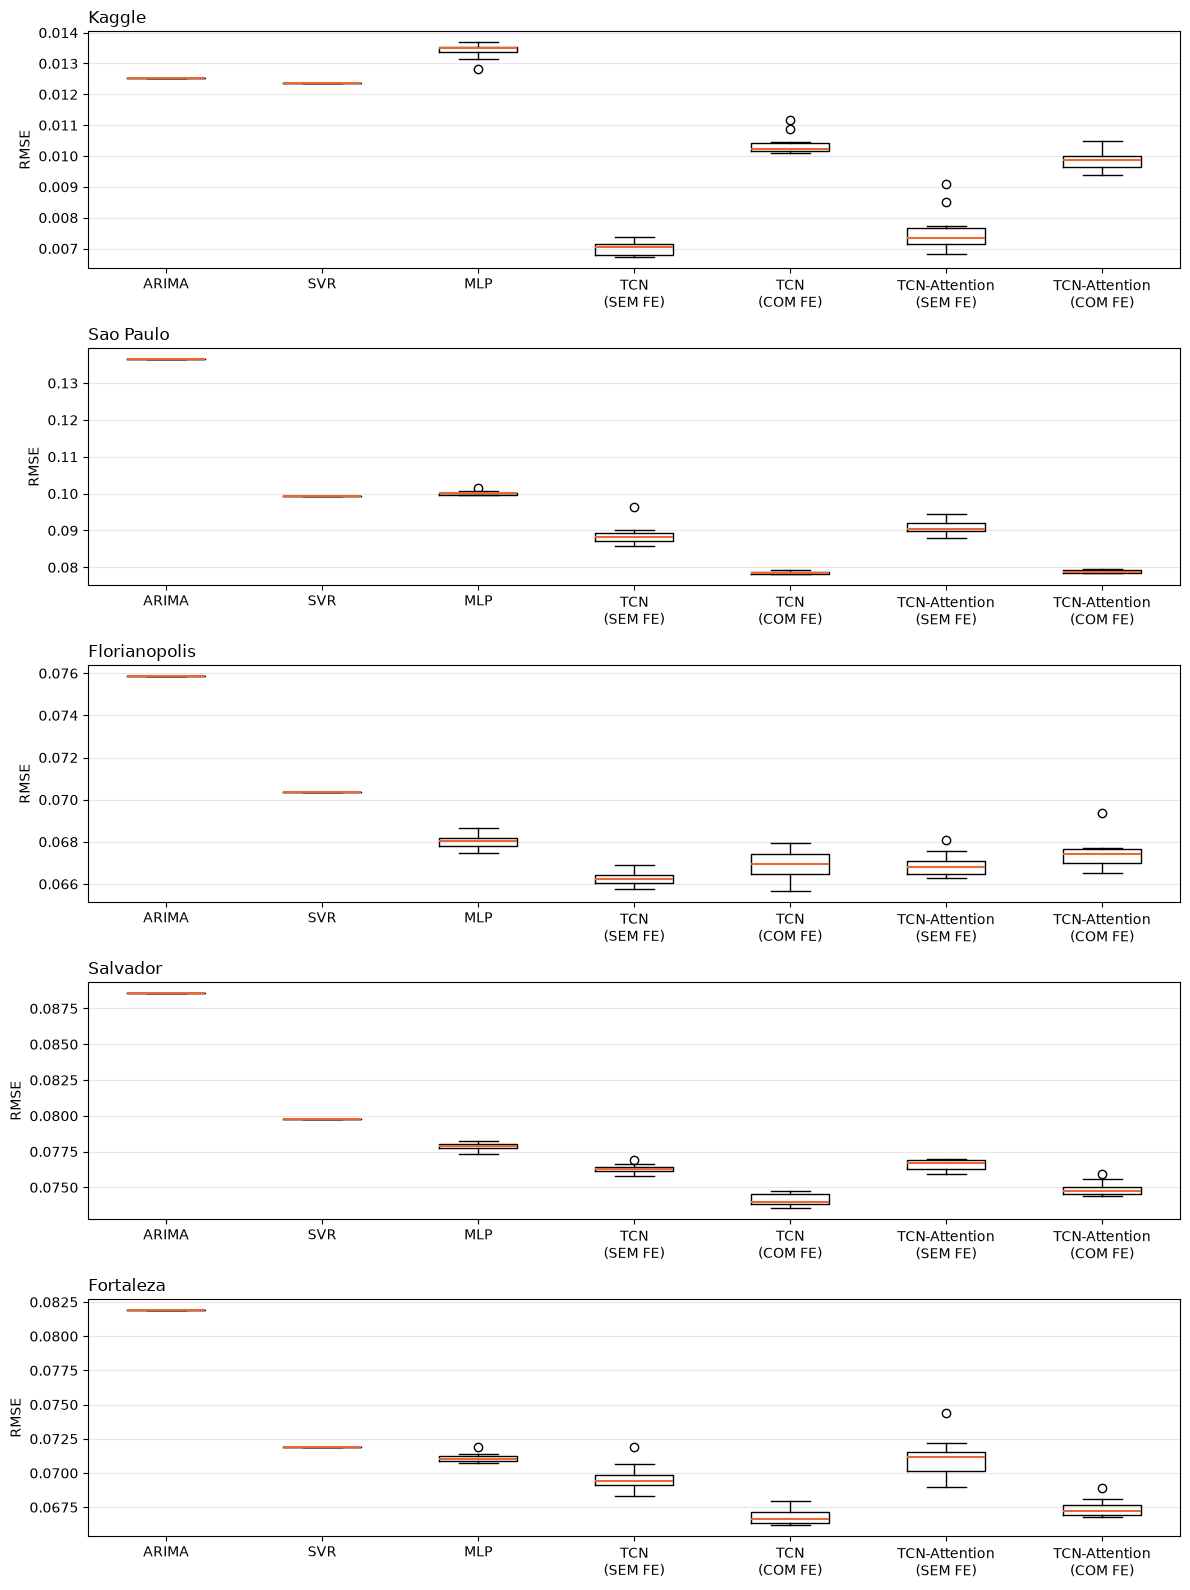

In [22]:
fig = graficos.boxplot_rmse(TABELA, list(SERIES), ORDEM, PASTA / "boxplot_rmse.png")

### 8.3 Friedman e Nemenyi
Os 5 datasets são os blocos e os 7 modelos são comparados pelo RMSE médio das 10 execuções (DEMŠAR, 2006). As barras ligam modelos cuja diferença de posto médio é menor que a distância crítica (CD).

Friedman χ² = 24.43, p = 0.000435 | CD = 4.03 (k = 7, N = 5)


,posto médio
modelo_cond,
TCN (COM FE),2.0
TCN (SEM FE),2.2
TCN-Attention (COM FE),2.6
TCN-Attention (SEM FE),3.2
SVR,5.6
MLP,5.6
ARIMA,6.8


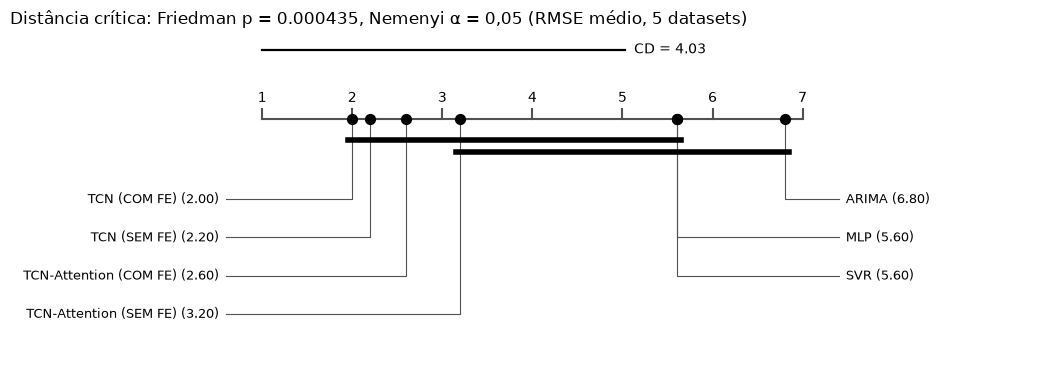

In [23]:
resultado = friedman_nemenyi(TABELA.groupby(["dataset", "modelo_cond"]).RMSE.mean().unstack()[ORDEM])
print(f"Friedman χ² = {resultado.qui_quadrado:.2f}, p = {resultado.p:.3g} | "
      f"CD = {resultado.distancia_critica:.2f} (k = {len(ORDEM)}, N = {resultado.n_blocos})")
display(resultado.postos.sort_values().round(2).to_frame("posto médio"))
fig = graficos.diagrama_distancia_critica(resultado, PASTA / "distancia_critica.png")

### 8.4 Real × TCN-Attention nos 150 primeiros instantes do teste
Para cada condição, aparece a execução de RMSE mediano. As horas sem medição ficam em branco na curva real.

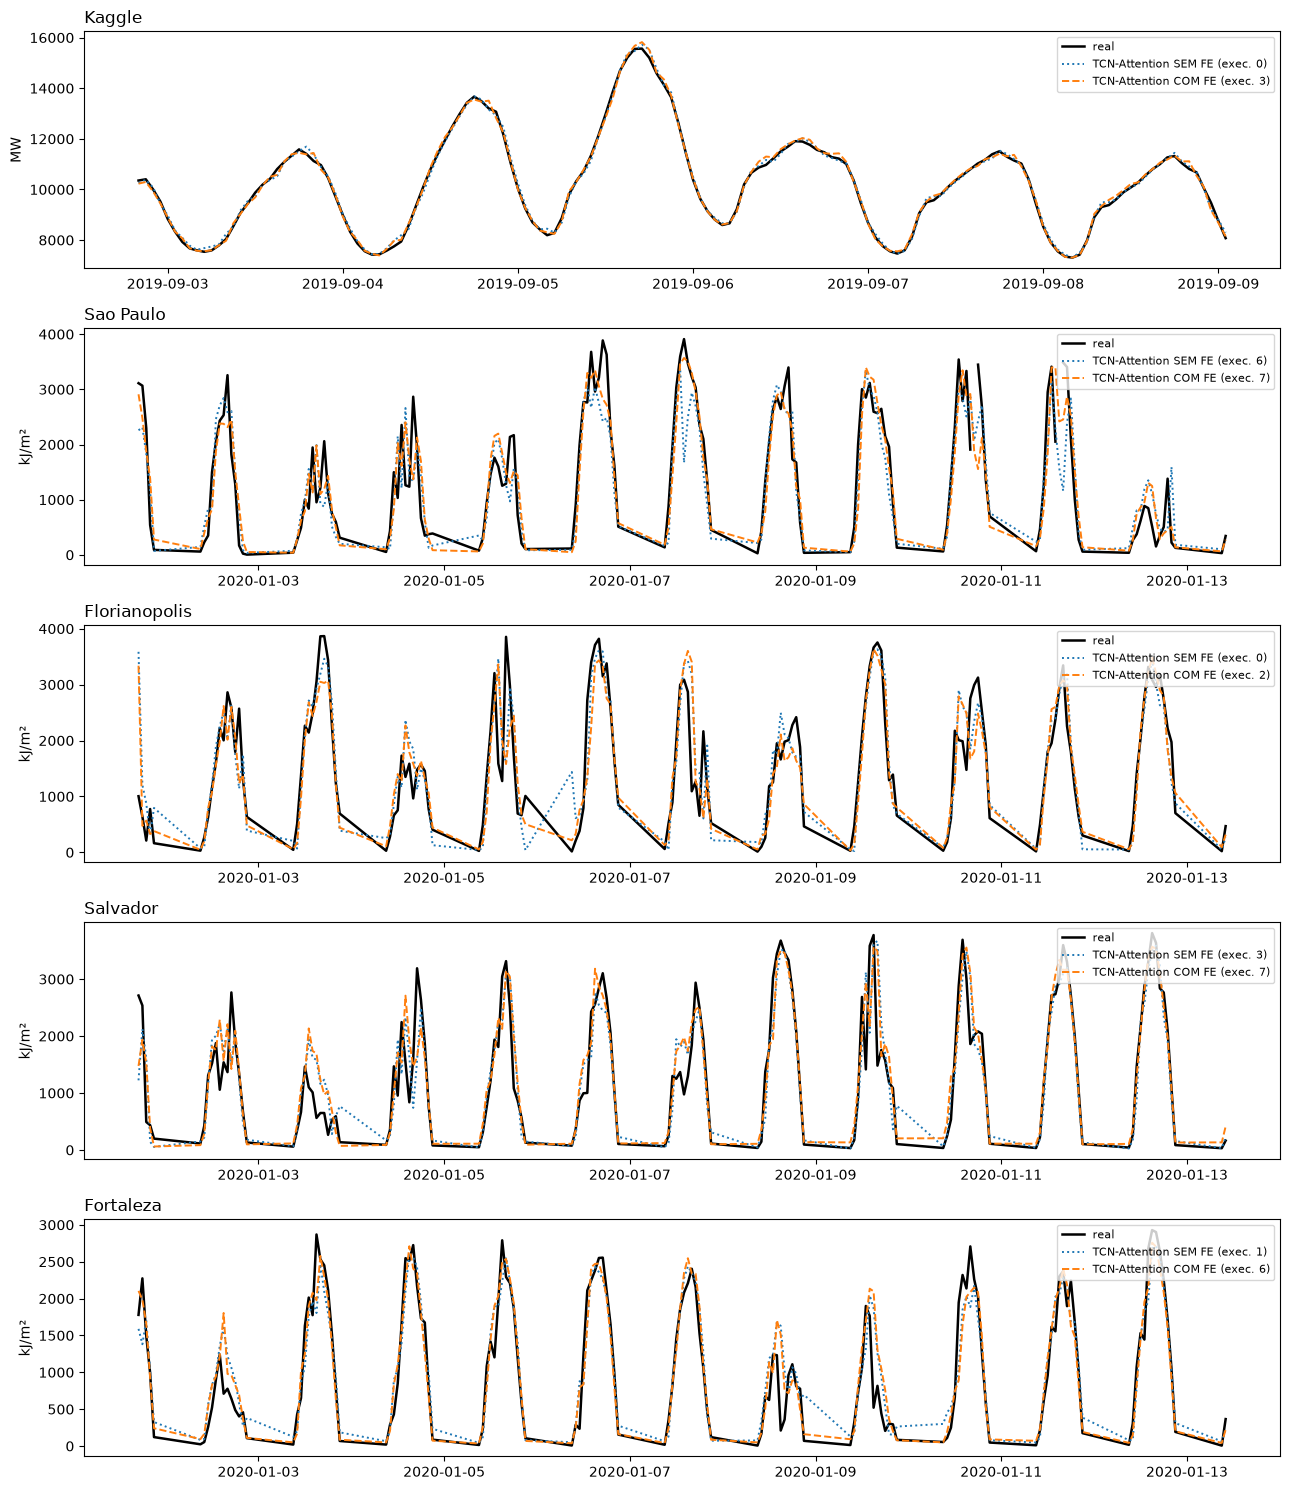

In [24]:
fig = graficos.real_vs_previsto(SERIES, registro, "TCN-Attention", caminho=PASTA / "forecast_tcn_attention.png")

## Referências
BAHDANAU, D.; CHO, K.; BENGIO, Y. Neural machine translation by jointly learning to align and translate. In: INTERNATIONAL CONFERENCE ON LEARNING REPRESENTATIONS, 3., 2015, San Diego. *Proceedings* [...]. San Diego: ICLR, 2015. Disponível em: https://arxiv.org/abs/1409.0473.

BAI, S.; KOLTER, J. Z.; KOLTUN, V. *An empirical evaluation of generic convolutional and recurrent networks for sequence modeling*. arXiv:1803.01271, 2018.

DEMŠAR, J. Statistical comparisons of classifiers over multiple data sets. *Journal of Machine Learning Research*, v. 7, p. 1-30, 2006.

DUFFIE, J. A.; BECKMAN, W. A. *Solar engineering of thermal processes*. 4. ed. Hoboken: John Wiley & Sons, 2013.

FALGE, E. et al. Gap filling strategies for defensible annual sums of net ecosystem exchange. *Agricultural and Forest Meteorology*, v. 107, n. 1, p. 43-69, 2001.

FRIEDMAN, M. The use of ranks to avoid the assumption of normality implicit in the analysis of variance. *Journal of the American Statistical Association*, v. 32, n. 200, p. 675-701, 1937.

HONNURVALI, M. S. et al. A TCN-Attention model for high-accuracy solar energy generation forecasting. *IEEE Open Access Journal of Power and Energy*, v. 13, p. 690-701, 2026. DOI: 10.1109/OAJPE.2026.3723147.

HYNDMAN, R. J.; KHANDAKAR, Y. Automatic time series forecasting: the forecast package for R. *Journal of Statistical Software*, v. 27, n. 3, p. 1-22, 2008.

INSTITUTO NACIONAL DE METEOROLOGIA. *Dados históricos anuais*. Brasília: INMET, [2026]. Disponível em: https://portal.inmet.gov.br/dadoshistoricos. Acesso em: 25 nov. 2026.

KINGMA, D. P.; BA, J. Adam: a method for stochastic optimization. In: INTERNATIONAL CONFERENCE ON LEARNING REPRESENTATIONS, 3., 2015, San Diego. *Proceedings* [...]. San Diego: ICLR, 2015. Disponível em: https://arxiv.org/abs/1412.6980.

LITTLE, R. J. A.; RUBIN, D. B. *Statistical analysis with missing data*. 3. ed. Hoboken: John Wiley & Sons, 2019.

NEMENYI, P. B. *Distribution-free multiple comparisons*. 1963. Tese (Doutorado) – Princeton University, Princeton, 1963.

PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825-2830, 2011.

SANTOS JÚNIOR, D. S. O. et al. Solar irradiance forecasting using dynamic ensemble selection. *Applied Sciences*, v. 12, n. 7, 3510, 2022. DOI: 10.3390/app12073510.

SPENCER, J. W. Fourier series representation of the position of the sun. *Search*, v. 2, n. 5, p. 172, 1971.

TIME series forecasting of solar energy. Kaggle, [20--]. Disponível em: https://www.kaggle.com/datasets/chaitanyakumar12/time-series-forecasting-of-solar-energy. Acesso em: 25 nov. 2026.

TUKEY, J. W. *Exploratory data analysis*. Reading: Addison-Wesley, 1977.